# My Vivino Project

Website: "https://www.vivino.com/en/"

Business problem:

Vivino is a wine marketplace where customers can discover and compare wines. With a large number of wines available, customers may find it difficult to identify wines that offer good value for money. By analysing wine prices, average ratings, popularity, and characteristics, Vivino could gain useful insights into customer ratings and help customers discover suitable wine alternatives.

Research question:

Is there a significant relationship between wine price and average customer rating in the scraped Vivino dataset, and can wine characteristics be used to recommend similar wines?

Hypotheses:

Null hypothesis (H₀): There is no statistically significant relationship between wine price and average customer rating in the scraped dataset.

Alternative hypothesis (H₁): There is a statistically significant relationship between wine price and average customer rating in the scraped dataset.

I will investigate this relationship using exploratory data analysis, visualisations, and statistical testing. I will then explore whether a content-based recommendation system can suggest similar wines using available characteristics such as wine type, country, region, and price.

# Importing All The Required Libraries

In [153]:
#pip install scikit-learn

In [154]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from sklearn.metrics.pairwise import cosine_similarity

### My Vivino Dataset

In [155]:
df = pd.read_csv("vivino_wines.csv")
df.head()

,vintage_id,wine_id,winery,wine_name,vintage_year,wine_type,region,country,rating_avg,rating_count,price,currency,vivino_url
0,156848268,6266660,Félix Solís,Mucho Más Tinto,N.V.,Red,Vino de España,Spain,4.1,120553,15.63,USD,https://www.vivino.com/w/6266660
1,1469676,21646,Fantini,Edizione Cinque Autoctoni,N.V.,Red,Abruzzo,Italy,4.3,78766,30.20,USD,https://www.vivino.com/w/21646
2,182492833,1655,Antinori,Pèppoli Chianti Classico,2025,Red,Chianti Classico,Italy,3.9,72772,31.04,USD,https://www.vivino.com/w/1655
3,179571044,22448,Ornellaia,Le Serre Nuove,2024,Red,Bolgheri,Italy,4.3,66223,81.25,USD,https://www.vivino.com/w/22448
4,173847458,19265,Produttori del Barbaresco,Barbaresco,2023,Red,Barbaresco,Italy,4.1,59711,43.26,USD,https://www.vivino.com/w/19265


# Cleaning The Dataset

In [156]:
df.shape

(720, 13)

In [157]:
df.columns

Index(['vintage_id', 'wine_id', 'winery', 'wine_name', 'vintage_year',
       'wine_type', 'region', 'country', 'rating_avg', 'rating_count', 'price',
       'currency', 'vivino_url'],
      dtype='object')

In [158]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   vintage_id    720 non-null    int64  
 1   wine_id       720 non-null    int64  
 2   winery        720 non-null    object 
 3   wine_name     720 non-null    object 
 4   vintage_year  713 non-null    object 
 5   wine_type     720 non-null    object 
 6   region        720 non-null    object 
 7   country       720 non-null    object 
 8   rating_avg    720 non-null    float64
 9   rating_count  720 non-null    int64  
 10  price         720 non-null    float64
 11  currency      720 non-null    object 
 12  vivino_url    720 non-null    object 
dtypes: float64(2), int64(3), object(8)
memory usage: 73.2+ KB


In [159]:
df.isnull().sum()

vintage_id      0
wine_id         0
winery          0
wine_name       0
vintage_year    7
wine_type       0
region          0
country         0
rating_avg      0
rating_count    0
price           0
currency        0
vivino_url      0
dtype: int64

In [160]:
df.duplicated().sum()

0

In [161]:
df[df["vintage_year"].isnull()]

,vintage_id,wine_id,winery,wine_name,vintage_year,wine_type,region,country,rating_avg,rating_count,price,currency,vivino_url
268,1650248,1223973,Santa Margherita,Prosecco Superiore di Valdobbiadene Brut,NaN,Sparkling,Conegliano-Valdobbiadene Prosecco Superiore,Italy,3.8,16375,31.72,USD,https://www.vivino.com/w/1223973
280,12865935,2922666,Le Mesnil,Blanc de Blancs Brut Champagne Grand Cru N.V,NaN,Sparkling,Champagne Grand Cru,France,4.1,10350,49.25,USD,https://www.vivino.com/w/2922666
306,1813677,1309984,Contadi Castaldi,Franciacorta Rosé,NaN,Sparkling,Franciacorta,Italy,3.9,5484,40.68,USD,https://www.vivino.com/w/1309984
329,1539359,1249745,Mosnel,Franciacorta Brut,NaN,Sparkling,Franciacorta,Italy,3.9,4080,43.26,USD,https://www.vivino.com/w/1249745
341,1518841,1156464,Bailly Lapierre,Crémant de Bourgogne Pinot Noir Brut,NaN,Sparkling,Crémant de Bourgogne,France,3.8,3306,29.59,USD,https://www.vivino.com/w/1156464
350,157423862,6425977,Nicolas Feuillatte,Réserve Exclusive Rosé Champagne,NaN,Sparkling,Champagne Grand Cru 'Chouilly',France,4.0,2939,71.72,USD,https://www.vivino.com/w/6425977
353,36020318,3758970,De Venoge,Princes Blanc de Blancs Champagne,NaN,Sparkling,Champagne,France,4.2,2899,99.63,USD,https://www.vivino.com/w/3758970


In [162]:
df["currency"].value_counts()

USD    720
Name: currency, dtype: int64

In [163]:
df[["price", "rating_avg"]].describe()

,price,rating_avg
count,720.000000,720.000000
mean,54.280264,3.979583
std,66.303539,0.258297
min,6.280000,3.100000
25%,25.100000,3.800000
50%,32.275000,4.000000
75%,55.980000,4.125000
max,487.700000,4.700000


# Data Visualization

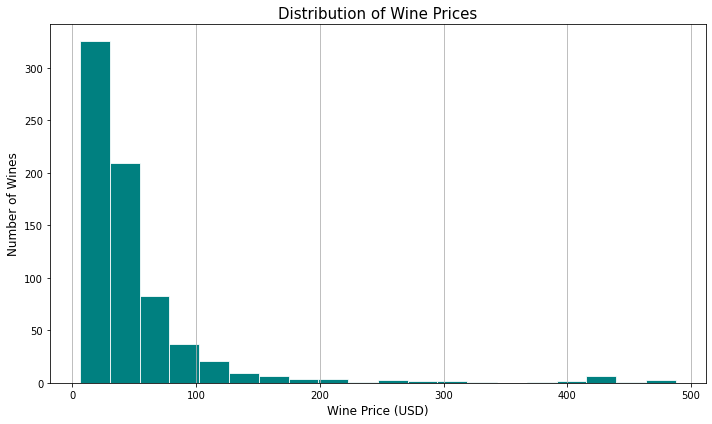

In [164]:
df['price'].hist(
    bins=20,
    figsize=(10, 6),
    color='teal',
    edgecolor='white',
    linewidth=0.8
)

plt.xlabel('Wine Price (USD)', fontsize=12)
plt.ylabel('Number of Wines', fontsize=12)
plt.title('Distribution of Wine Prices', fontsize=15)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [165]:
p95 = df['price'].quantile(0.95)
print(p95)

145.96999999999974


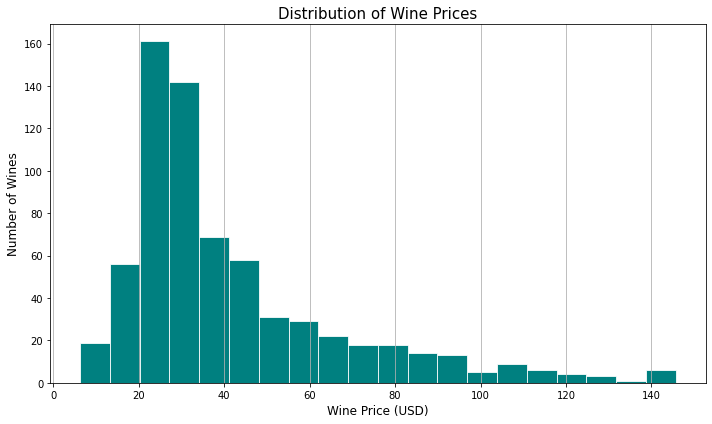

In [166]:
df[df['price'] <= p95]['price'].hist(bins=20,
    figsize=(10, 6),
    color='teal',
    edgecolor='white',
    linewidth=0.8
)

plt.xlabel('Wine Price (USD)', fontsize=12)
plt.ylabel('Number of Wines', fontsize=12)
plt.title('Distribution of Wine Prices', fontsize=15)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

The wine price distribution is right-skewed, meaning most wines are concentrated at lower prices, while a smaller number of expensive wines extend the distribution to the right. The mean price is higher than the median, which supports this observation. I also created a second histogram focusing on the central 95% of prices to make the main distribution easier to examine.

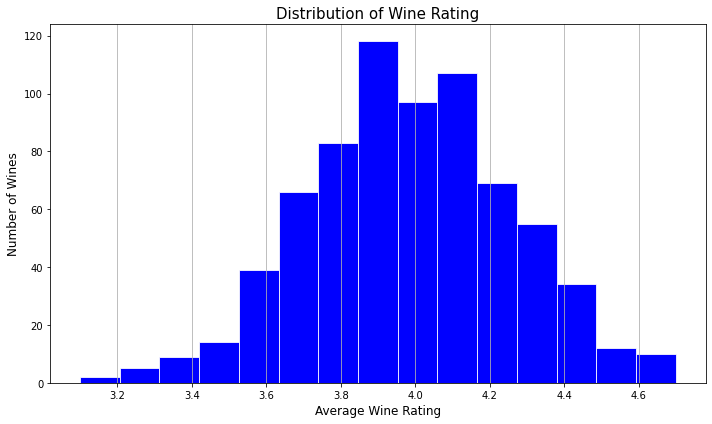

In [167]:
df['rating_avg'].hist(
    bins=15,
    figsize=(10, 6),
    color='blue',
    edgecolor='white',
    linewidth=0.8
)

plt.xlabel('Average Wine Rating', fontsize=12)
plt.ylabel('Number of Wines', fontsize=12)
plt.title('Distribution of Wine Rating', fontsize=15)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

The rating histogram shows that most wines have average ratings between approximately 3.8 and 4.2. The ratings are more concentrated than the prices, with fewer wines at the lower and upper ends of the rating range. This suggests that most wines in the dataset have relatively similar average ratings.

Is there a significant relationship between wine price and average customer rating?

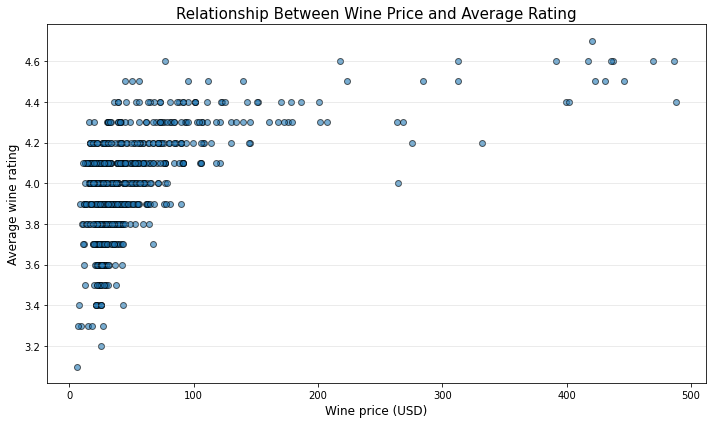

In [168]:
plt.figure(figsize=(10, 6))
scatter = plt.scatter(x=df['price'], y=df['rating_avg'], alpha=0.6, edgecolors='black')

plt.xlabel('Wine price (USD)', fontsize=12)
plt.ylabel('Average wine rating', fontsize=12)
plt.title('Relationship Between Wine Price and Average Rating', fontsize=15)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()


plt.show()

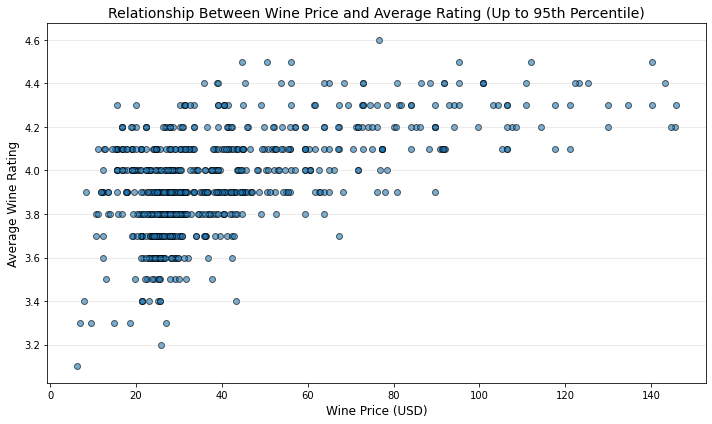

In [169]:
df_p95 = df[df['price'] <= p95]

plt.figure(figsize=(10, 6))

scatter_p95 = plt.scatter(
    x=df_p95['price'],
    y=df_p95['rating_avg'],
    alpha=0.6,
    edgecolors='black'
)

plt.xlabel('Wine Price (USD)', fontsize=12)
plt.ylabel('Average Wine Rating', fontsize=12)
plt.title(
    'Relationship Between Wine Price and Average Rating (Up to 95th Percentile)',
    fontsize=14
)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


The scatter plot suggests a possible positive relationship between wine price and average rating, as some of the higher-priced wines have higher ratings. However, the points are widely scattered, and most wines are concentrated around prices of $10–$50 and ratings of approximately 3.6–4.2. The most expensive wines do not consistently have the highest ratings. Further statistical analysis is needed to determine whether the relationship between price and rating is significant.

### Correlation Between Wine Price and Average Rating

In [170]:
correlation = df['price'].corr(df['rating_avg'])
print(f"Correlation: {correlation:.4f}")

Correlation: 0.5503


The Pearson correlation coefficient between wine price and average rating is approximately 0.55. This indicates a moderate positive linear relationship between the two variables. In general, higher-priced wines tend to have higher average ratings, although this is not true for every wine. Further statistical testing is needed to determine whether the observed relationship is statistically significant.

In [171]:
pearson_correlation = stats.pearsonr(df['price'], df['rating_avg'])
print(f"Pearson correlation coefficient (r): {pearson_correlation[0]:.4f}")
print(f"P-value: {pearson_correlation[1]:.4f}")

Pearson correlation coefficient (r): 0.5503
P-value: 0.0000


Pearson Correlation Test

The Pearson correlation coefficient was 0.5503, indicating a moderate positive linear relationship between wine price and average rating. The p-value was displayed as 0.0000 when rounded to four decimal places, meaning it was smaller than 0.0001. Since the p-value is below the significance level of 0.05, I reject the null hypothesis of zero population linear correlation. This provides statistical evidence of a relationship between wine price and average rating in the population represented by the sample, subject to the test assumptions. However, correlation does not imply causation.

In [172]:
spearman_correlation = stats.spearmanr(df['price'], df['rating_avg'])
print(spearman_correlation)

SpearmanrResult(correlation=0.5765974973230765, pvalue=4.987789380062678e-65)


### Checking the Impact of Outliers on Correlation

In [173]:
correlation_95 = df_p95['price'].corr(df_p95['rating_avg'])
spearman_correlation_95 = stats.spearmanr(df_p95['price'], df_p95['rating_avg'])
print(f"Correlation 95%: {correlation_95:.4f}")
print(spearman_correlation_95)

Correlation 95%: 0.5565
SpearmanrResult(correlation=0.5131684296408027, pvalue=3.240248081199892e-47)


Impact of Expensive Wines on Correlation

To check whether expensive wines were affecting the results, I recalculated the Pearson and Spearman correlations after excluding wines above the 95th percentile price($145.97).

The Pearson correlation increased slightly from 0.5503 to 0.5565, while the Spearman correlation decreased from 0.5766 to 0.5132.

This shows that removing the most expensive wines had very little effect on the linear relationship, although the ranking relationship became slightly weaker. Both correlations remained moderately positive, suggesting that the relationship between wine price and average rating is not entirely driven by the most expensive wines.

### Wine type distribution

In [174]:
diff_wines = df['wine_type'].value_counts()
print(diff_wines)

Dessert      120
Red          120
Fortified    120
White        120
Sparkling    120
Rose         120
Name: wine_type, dtype: int64


In [175]:
diff_winesavg = df.groupby('wine_type')['price'].mean().sort_values()
print(diff_winesavg.round(2))

wine_type
Rose         28.31
White        34.75
Red          44.84
Sparkling    65.21
Dessert      68.74
Fortified    83.83
Name: price, dtype: float64


Average Wine Price by Type

I grouped the wines by their type and calculated the average price for each category. Fortified wines had the highest average price at 83.83  , followed by dessert wines at 68.74 and sparkling wines at 65.21. Rose wines had the lowest average price at 28.31.

These results show that average prices vary between wine types in my dataset. However, the averages may be influenced by expensive wines within each category.

### Bar chart comparing average prices across wine types

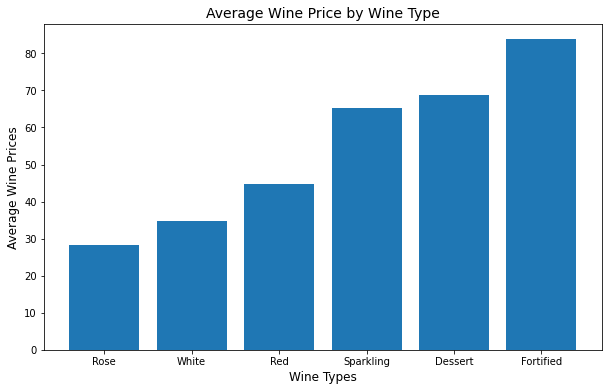

In [176]:
plt.figure(figsize=(10, 6))
plt.bar(
    x=diff_winesavg.index,
    height=diff_winesavg.values,
)
plt.xlabel('Wine Types', fontsize=12)
plt.ylabel('Average Wine Prices', fontsize=12) 
plt.title(
    'Average Wine Price by Wine Type', 
    fontsize=14
)
plt.show()

### Average Wine Rating by Type

In [177]:
diff_winesavgrat = df.groupby('wine_type')['rating_avg'].mean().sort_values()
print(diff_winesavgrat.round(2))

wine_type
Rose         3.81
White        3.89
Red          3.95
Sparkling    4.00
Fortified    4.09
Dessert      4.14
Name: rating_avg, dtype: float64


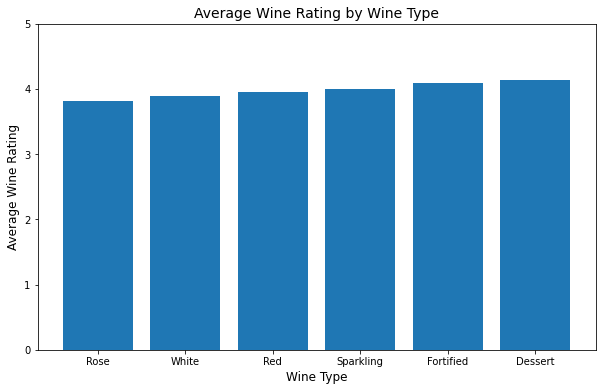

In [178]:
plt.figure(figsize=(10, 6))
plt.bar(
    x=diff_winesavgrat.index,
    height=diff_winesavgrat.values,
)
plt.xlabel('Wine Type', fontsize=12)
plt.ylabel('Average Wine Rating', fontsize=12) 
plt.title(
    'Average Wine Rating by Wine Type', 
    fontsize=14
)

plt.ylim(0, 5)

plt.show()

I grouped the wines by their type and calculated the average rating for each category. Dessert wines had the highest average rating at 4.14, while rosé wines had the lowest at 3.81.

The differences between the categories were relatively small, with all average ratings falling between 3.81 and 4.14.

When comparing the average price and rating charts, I noticed that more expensive wine types generally had higher average ratings. However, fortified wines had the highest average price, while dessert wines had the highest average rating. This shows that higher prices do not always correspond to higher ratings.

### Wine Distribution by Country

In [179]:
wines_country = pd.value_counts(df['country'])
print(wines_country)

Italy           385
France          156
Portugal         92
Spain            43
Austria          19
Argentina         7
South Africa      7
Germany           3
Hungary           2
Greece            2
Chile             2
New Zealand       1
Australia         1
Name: country, dtype: int64


I counted the number of wines from each country and found that Italy has the most wines with 385, followed by France with 156 and Portugal with 92. These three countries account for approximately 87.9% of the dataset.

The distribution is uneven, with some countries having very few wines. This is important because comparing average prices or ratings between countries with very different sample sizes may lead to misleading conclusions. The results also reflect the wines collected during scraping rather than the actual distribution of wines on Vivino.

In [180]:
eligible_countries = wines_country[wines_country >= 10].index

filtered_countries = df[df['country'].isin(eligible_countries)]

avgprice_country = filtered_countries.groupby('country')['price'].mean().sort_values()
print(avgprice_country.round(2))

country
Spain       26.03
Austria     31.42
Italy       38.18
France      82.15
Portugal    97.25
Name: price, dtype: float64


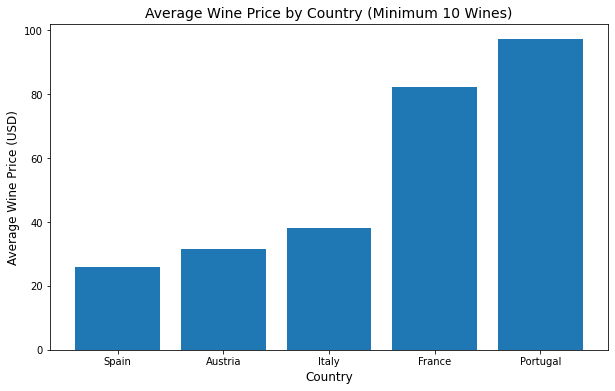

In [181]:
plt.figure(figsize=(10, 6))
plt.bar(
    x=avgprice_country.index,
    height=avgprice_country.values,
)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Average Wine Price (USD)', fontsize=12) 
plt.title(
    'Average Wine Price by Country (Minimum 10 Wines)', 
    fontsize=14
)

plt.show()

### Average Wine Price by Country

I compared the average wine prices across countries that had at least 10 wines in my dataset. Portugal had the highest average price at 97.25, followed by France at 82.15. Spain had the lowest average price at 26.03.

There were noticeable differences between countries, especially between Portugal and Spain. However, these results may be influenced by the types of wines collected and unusually expensive wines within each country. Therefore, they should not be treated as representative of all wines produced in those countries.

### Average Wine Rating by Country

In [182]:
avgrating_country = filtered_countries.groupby('country')['rating_avg'].mean().sort_values()
print(avgrating_country.round(2))

country
Spain       3.90
Italy       3.90
Austria     4.05
France      4.10
Portugal    4.13
Name: rating_avg, dtype: float64


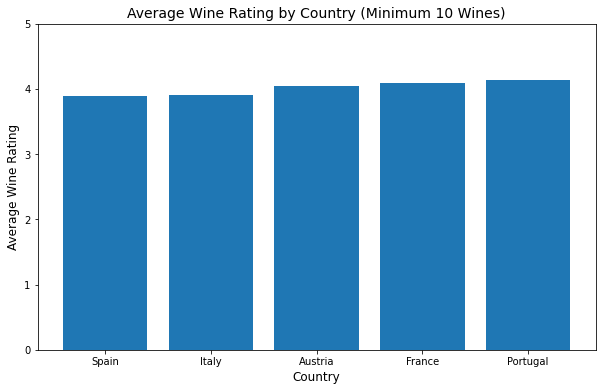

In [183]:
plt.figure(figsize=(10, 6))
plt.bar(
    x=avgrating_country.index,
    height=avgrating_country.values,
)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Average Wine Rating', fontsize=12) 
plt.title(
    'Average Wine Rating by Country (Minimum 10 Wines)', 
    fontsize=14
)

plt.ylim(0, 5)

plt.show()

I compared the average wine ratings for countries with at least 10 wines in my dataset. Portugal had the highest average rating at 4.13, followed by France at 4.10. Spain and Italy had the lowest average ratings at approximately 3.90.

When comparing prices and ratings, I noticed that Portugal and France had both higher average prices and higher average ratings. However, Austria had a relatively low average price of $31.42 while maintaining an average rating of 4.05.

This suggests that although higher-priced countries sometimes have higher-rated wines, the relationship is not consistent across every country. The differences in average ratings were also relatively small. These findings only represent the wines collected in my dataset.

### Wine Popularity Analysis

In [184]:
df['rating_count'].describe().round(2)

count       720.00
mean       5852.12
std       13055.09
min          30.00
25%         377.25
50%        2742.50
75%        5427.00
max      149763.00
Name: rating_count, dtype: float64

I examined the number of ratings each wine received to understand how popularity varies across the dataset.

The average number of ratings was approximately 5,852, while the median was only 2,743. This suggests that the distribution is right-skewed, with some wines receiving significantly more ratings than others.

The minimum rating count was 30, while the maximum was 149,763, showing a large difference in the number of ratings between wines.

This information could be useful for the recommendation system because wines with more ratings generally provide more evidence about customer opinions, although a higher rating count does not necessarily mean better quality.

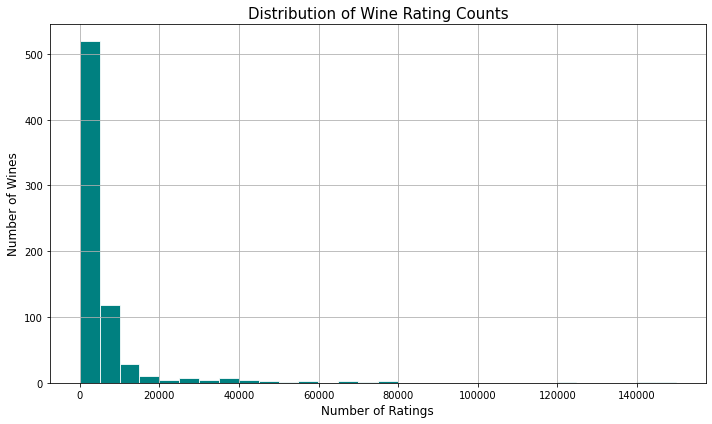

In [185]:
df['rating_count'].hist(
    bins=30,
    figsize=(10, 6),
    color='teal',
    edgecolor='white',
    linewidth=0.8
)

plt.xlabel('Number of Ratings', fontsize=12)
plt.ylabel('Number of Wines', fontsize=12)
plt.title('Distribution of Wine Rating Counts', fontsize=15)
plt.tight_layout()
plt.show()

### Distribution of Wine Rating Counts

The histogram shows that the number of ratings per wine is strongly right-skewed. Most wines have relatively low rating counts, while a small number of wines have received significantly more ratings.

The mean rating count is approximately 5,852, compared with a median of 2,743. This difference supports the observation that a few highly rated-count wines are pulling the average upward.

Because the distribution contains extreme values, I will also examine the central 95% of rating counts to better understand how most wines are distributed.

In [186]:
r95 = df['rating_count'].quantile(0.95)
print(r95.round(2))

27665.55


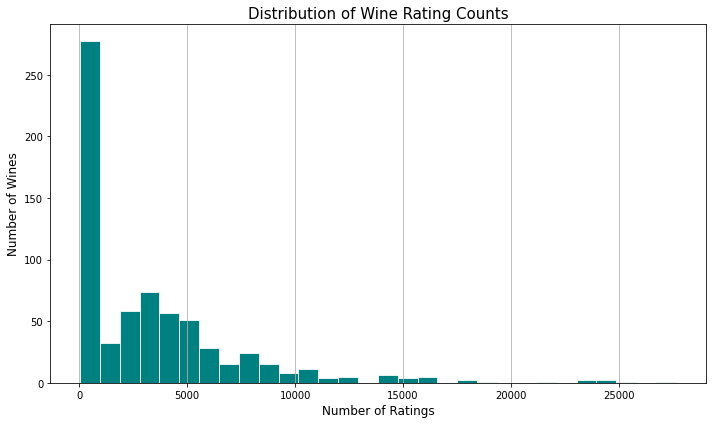

In [187]:
df[df['rating_count'] <= r95]['rating_count'].hist(bins=30,
    figsize=(10, 6),
    color='teal',
    edgecolor='white',
    linewidth=0.8
)

plt.xlabel('Number of Ratings', fontsize=12)
plt.ylabel('Number of Wines', fontsize=12)
plt.title('Distribution of Wine Rating Counts', fontsize=15)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Rating Count Distribution (95th Percentile)

I calculated the 95th percentile of rating counts, which was approximately 27,666. I then created another histogram excluding the top 5% of wines by rating count.

The distribution remained right-skewed, with most wines having relatively low numbers of ratings. However, removing the extreme values made it easier to see how the majority of wines were distributed.

This suggests that popularity, measured by the number of ratings, varies considerably across wines in my dataset.

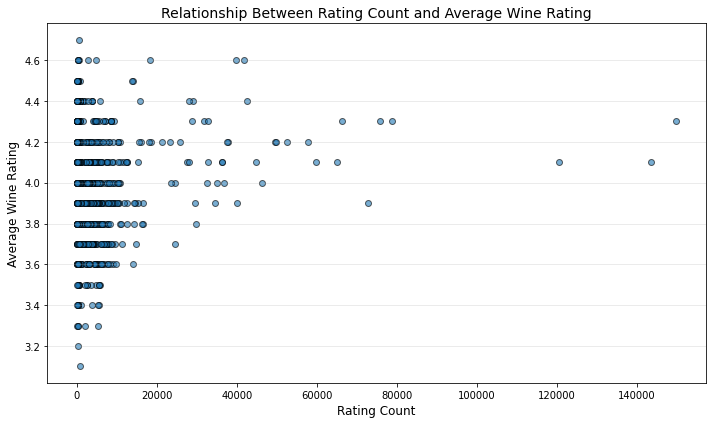

In [188]:
plt.figure(figsize=(10, 6))

plt.scatter(
    x=df['rating_count'],
    y=df['rating_avg'],
    alpha=0.6,
    edgecolors='black'
)

plt.xlabel('Rating Count', fontsize=12)
plt.ylabel('Average Wine Rating', fontsize=12)
plt.title(
    'Relationship Between Rating Count and Average Wine Rating',
    fontsize=14
)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Relationship Between Rating Count and Average Wine Rating

I created a scatter plot to investigate whether wines with more ratings tend to have higher average ratings.

Most wines were concentrated at lower rating counts, while a small number had significantly more ratings. Average ratings varied considerably among wines with fewer ratings.

The scatter plot did not show a clear strong linear relationship between rating count and average rating. Wines with the highest rating counts did not consistently have the highest average ratings.

Further correlation analysis is needed to determine the strength and direction of this relationship.

In [189]:
correlation = df['rating_count'].corr(df['rating_avg'])
spearman_correlation = stats.spearmanr(df['rating_count'], df['rating_avg'])
print(f"Correlation: {correlation:.4f}")
print(spearman_correlation)

Correlation: 0.1255
SpearmanrResult(correlation=-0.0789896824136158, pvalue=0.034078224203404214)


### Correlation Between Rating Count and Average Rating

I calculated Pearson and Spearman correlations to investigate whether wines with more ratings tend to have higher average ratings.

The Pearson correlation was 0.1255, indicating a very weak positive linear relationship. The Spearman correlation was -0.0790, indicating a very weak negative monotonic relationship.

The Spearman p-value was approximately 0.0341, which is below the significance level of 0.05. However, the correlation was extremely weak, so the relationship may have little practical importance.

The difference between Pearson and Spearman may be influenced by wines with unusually high rating counts. Overall, the results suggest that the number of ratings is not strongly associated with average wine rating in this dataset.

In [190]:
df_r95 = df[df['rating_count'] <= r95]

correlation_df_r95 = df_r95['rating_count'].corr(df_r95['rating_avg'])
spearman_correlation_df_r95 = stats.spearmanr(df_r95['rating_count'], df_r95['rating_avg'])

print(f"Correlation: {correlation_df_r95:.4f}")
print(spearman_correlation_df_r95)

Correlation: -0.0392
SpearmanrResult(correlation=-0.1581313612084828, pvalue=3.2632392615690964e-05)


### Impact of Highly Rated-Count Wines on Correlation

To investigate whether wines with unusually high numbers of ratings were affecting the relationship between popularity and average rating, I excluded wines above the 95th percentile of rating count.

The Pearson correlation changed from 0.1255 to -0.0392, suggesting that the most frequently rated wines were influencing the original positive linear correlation.

The Spearman correlation decreased from -0.0790 to -0.1581, indicating a slightly stronger but still weak negative relationship.

The filtered Spearman p-value was approximately 0.000033, showing statistical evidence of a negative monotonic association under the test assumptions. However, the effect size remained small.

Overall, the results suggest that rating count is not strongly associated with average wine rating in this dataset. Wines with more ratings do not necessarily receive higher average scores.

In [191]:
df[df['vintage_year'].isnull()]

,vintage_id,wine_id,winery,wine_name,vintage_year,wine_type,region,country,rating_avg,rating_count,price,currency,vivino_url
268,1650248,1223973,Santa Margherita,Prosecco Superiore di Valdobbiadene Brut,NaN,Sparkling,Conegliano-Valdobbiadene Prosecco Superiore,Italy,3.8,16375,31.72,USD,https://www.vivino.com/w/1223973
280,12865935,2922666,Le Mesnil,Blanc de Blancs Brut Champagne Grand Cru N.V,NaN,Sparkling,Champagne Grand Cru,France,4.1,10350,49.25,USD,https://www.vivino.com/w/2922666
306,1813677,1309984,Contadi Castaldi,Franciacorta Rosé,NaN,Sparkling,Franciacorta,Italy,3.9,5484,40.68,USD,https://www.vivino.com/w/1309984
329,1539359,1249745,Mosnel,Franciacorta Brut,NaN,Sparkling,Franciacorta,Italy,3.9,4080,43.26,USD,https://www.vivino.com/w/1249745
341,1518841,1156464,Bailly Lapierre,Crémant de Bourgogne Pinot Noir Brut,NaN,Sparkling,Crémant de Bourgogne,France,3.8,3306,29.59,USD,https://www.vivino.com/w/1156464
350,157423862,6425977,Nicolas Feuillatte,Réserve Exclusive Rosé Champagne,NaN,Sparkling,Champagne Grand Cru 'Chouilly',France,4.0,2939,71.72,USD,https://www.vivino.com/w/6425977
353,36020318,3758970,De Venoge,Princes Blanc de Blancs Champagne,NaN,Sparkling,Champagne,France,4.2,2899,99.63,USD,https://www.vivino.com/w/3758970


### Handling Missing Vintage Years

During data cleaning, I found 7 wines with missing vintage-year values out of 720 wines, representing approximately 0.97% of the dataset.

All 7 wines belonged to the sparkling wine category. Some sparkling wines are non-vintage, meaning they do not have one specific harvest year.

I decided to keep these wines because their other important features, including price, rating, wine type, and country, were available. I also decided not to replace the missing years with estimated values because doing so could introduce inaccurate information.

For the recommendation system, I will either exclude vintage year as a feature or handle the missing values appropriately if the feature is needed.

### Data-Quality Check

In [192]:
invalid_wines = df[
    (df['price'] <= 0) |
    (df['rating_avg'] < 1) |
    (df['rating_avg'] > 5) |
    (df['rating_count'] <= 0)
]

print(invalid_wines)
print("Number of invalid wines:", len(invalid_wines))

Empty DataFrame
Columns: [vintage_id, wine_id, winery, wine_name, vintage_year, wine_type, region, country, rating_avg, rating_count, price, currency, vivino_url]
Index: []
Number of invalid wines: 0


This confirms that the dataset contains no prices of $0 or less, no average ratings outside 1–5, and no rating counts of 0 or less.

### Wine Recommendation System

#### Model 1: Basic Content-Based Recommendation System.

In [193]:
similarwines_df = df[['wine_type', 'country', 'region']]
similarwines_df = pd.get_dummies(similarwines_df)
similarwines_df.head()

,wine_type_Dessert,wine_type_Fortified,wine_type_Red,wine_type_Rose,wine_type_Sparkling,wine_type_White,country_Argentina,country_Australia,country_Austria,country_Chile,...,region_Vin Santo del Chianti,region_Vin Santo del Chianti Classico,region_Vin de France,region_Vinho Verde,region_Vino Nobile di Montepulciano,region_Vino d'Italia,region_Vino de España,region_Western Cape,region_Wine of Greece,region_delle Venezie
0,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
1,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [194]:
similarity_matrix = cosine_similarity(similarwines_df)
print(similarity_matrix.shape)
print(similarity_matrix[:5, :5])

(720, 720)
[[1.         0.33333333 0.33333333 0.33333333 0.33333333]
 [0.33333333 1.         0.66666667 0.66666667 0.66666667]
 [0.33333333 0.66666667 1.         0.66666667 0.66666667]
 [0.33333333 0.66666667 0.66666667 1.         0.66666667]
 [0.33333333 0.66666667 0.66666667 0.66666667 1.        ]]


In [195]:
def recommend_wines(wine_index):
    similarity_score = similarity_matrix[wine_index]

    indexed_scores = list(enumerate(similarity_score))
    
    similarity_score = sorted(indexed_scores, key=lambda x: x[1], reverse=True)
    
    similarity_score = [x for x in similarity_score if x[0] != wine_index]

    top_5 = similarity_score[:5]
    
    top_wines = []
    
    for tup in top_5:
        wine_index_result = tup[0]
        wine_name = df.iloc[wine_index_result]['wine_name']
        wine_type = df.iloc[wine_index_result]['wine_type']
        wine_country = df.iloc[wine_index_result]['country']
        wine_region = df.iloc[wine_index_result]['region']
        
        wine_similarity_score = tup[1]
        
        wine_info = {
            'wine_name': wine_name,
            'wine_type': wine_type,
            'country': wine_country,
            'region': wine_region,
            'similarity_score': wine_similarity_score
        }
        
        
        top_wines.append(wine_info)
    
    recommendations_df = pd.DataFrame(top_wines)
    return recommendations_df
         
recommend_wines(0)

,wine_name,wine_type,country,region,similarity_score
0,Kingpin,Red,Spain,Vino de España,1.000000
1,Mucho Más Tinto - Black Edition,Red,Spain,Vino de España,1.000000
2,Mucho Mas Gold,Red,Spain,Vino de España,1.000000
3,The Guv’nor,Red,Spain,Valdepeñas,0.666667
4,El Cortez Xo Extra Ordinario,Red,Spain,Valencia,0.666667


In [196]:
recommend_wines(120)

,wine_name,wine_type,country,region,similarity_score
0,Viura - Verdejo,White,Spain,Castilla,1.000000
1,The Guv'nor Blanco,White,Spain,Castilla,1.000000
2,Rioja Blanco,White,Spain,Rioja,0.666667
3,Rías Baixas Albariño Lias,White,Spain,Rías Baixas,0.666667
4,Viura - Chardonnay,White,Spain,Vino de España,0.666667


In [197]:
recommend_wines(240)

,wine_name,wine_type,country,region,similarity_score
0,Impérial Brut Champagne,Sparkling,France,Champagne,1.0
1,Special Cuvée Brut Aÿ Champagne,Sparkling,France,Champagne,1.0
2,La Cuvée Brut Champagne,Sparkling,France,Champagne,1.0
3,Brut (Réserve) Champagne,Sparkling,France,Champagne,1.0
4,Grand Brut Champagne,Sparkling,France,Champagne,1.0


In [198]:
recommend_wines(360)

,wine_name,wine_type,country,region,similarity_score
0,Tramari Just One More Glass Amore Mio,Rose,Italy,Vino d'Italia,1.000000
1,Cinquanta Collezione,Red,Italy,Vino d'Italia,0.666667
2,Rosso,Red,Italy,Vino d'Italia,0.666667
3,Rosa dei Masi Rosato Trevenezie,Rose,Italy,Trevenezie,0.666667
4,Maremma Toscana Rosato,Rose,Italy,Maremma Toscana,0.666667


#### Model 2: Weighted Content-Based Recommendation System

In [199]:
# Copy the encoded data so Model 1 stays unchanged
weighted_df = similarwines_df.copy()

# Set the importance of each wine feature
weights = {
    'wine_type_': 0.60,
    'country_': 0.25,
    'region_': 0.15
}

# Apply the weights to the encoded columns
for column in weighted_df.columns:
    for feature, weight in weights.items():
        if column.startswith(feature):
            weighted_df[column] = weighted_df[column].astype(float) * np.sqrt(weight)
            break

# Calculate the new weighted similarity matrix
weighted_similarity_matrix = cosine_similarity(weighted_df)

# Recommend the 5 most similar wines
def recommend_weighted_wines(wine_index):
    similarity_scores = weighted_similarity_matrix[wine_index]

    indexed_scores = list(enumerate(similarity_scores))

    sorted_scores = sorted(
        indexed_scores,
        key=lambda x: x[1],
        reverse=True
    )

    filtered_scores = [
        x for x in sorted_scores if x[0] != wine_index
    ]

    top_5 = filtered_scores[:5]

    top_wines = []

    for tup in top_5:
        wine_index_result = tup[0]

        wine_info = {
            'wine_name': df.iloc[wine_index_result]['wine_name'],
            'wine_type': df.iloc[wine_index_result]['wine_type'],
            'country': df.iloc[wine_index_result]['country'],
            'region': df.iloc[wine_index_result]['region'],
            'similarity_score': round(float(tup[1]), 4)
        }

        top_wines.append(wine_info)

    return pd.DataFrame(top_wines)

# Test Model 2
recommend_weighted_wines(360)    

,wine_name,wine_type,country,region,similarity_score
0,Tramari Just One More Glass Amore Mio,Rose,Italy,Vino d'Italia,1.00
1,Rosa dei Masi Rosato Trevenezie,Rose,Italy,Trevenezie,0.85
2,Maremma Toscana Rosato,Rose,Italy,Maremma Toscana,0.85
3,Cerasuolo d'Abruzzo Rosé (Tralcetto),Rose,Italy,Cerasuolo d'Abruzzo,0.85
4,Cirò Rosato (Segno),Rose,Italy,Cirò,0.85


### Comparison Between Model 1 and Model 2

I developed two content-based wine recommendation models using wine type, country, and region.

Model 1 used cosine similarity with equal importance assigned to all three features. During testing, I noticed that the system sometimes recommended wines of a different type because matching country and region could produce the same similarity score as matching wine type and country.

To improve this, I developed Model 2 using weighted cosine similarity. I assigned 60% importance to wine type, 25% to country, and 15% to region.

When testing wine 360, Model 1 recommended three Rosé wines and two Red wines. Model 2 recommended five Rosé wines, all from Italy.

This improved the same-type recommendation rate from 60% to 100% for this test case.

The results suggest that feature weighting can improve recommendations when wine type is considered the most important characteristic. However, further testing is needed to determine whether this improvement is consistent across the dataset.

In [200]:
def evaluate_model(recommend_function):
    total_matches = 0
    total_recommendations = 0

    for wine in range(len(df)):
        original_wine_type = df.iloc[wine]['wine_type']


        recommendations = recommend_function(wine)

        
        matches = (recommendations['wine_type'] == original_wine_type).sum()

        total_matches += matches
        total_recommendations += len(recommendations)

    # Calculate the overall matching percentage
    same_type_rate = (total_matches / total_recommendations) * 100

    return round(same_type_rate, 2)


# Evaluate Model 1
model_1_score = evaluate_model(recommend_wines)

# Evaluate Model 2
model_2_score = evaluate_model(recommend_weighted_wines)


print(f"Model 1 Same-Type Recommendation Rate: {model_1_score}%")
print(f"Model 2 Same-Type Recommendation Rate: {model_2_score}%")

Model 1 Same-Type Recommendation Rate: 94.08%
Model 2 Same-Type Recommendation Rate: 100.0%


### Recommendation System Evaluation

To evaluate the recommendation systems, I tested both models using all 720 wines in the dataset. Each model generated five recommendations per wine, resulting in 3,600 recommendations per model.

I measured the percentage of recommendations that matched the original wine's type.

**Results:**
- Model 1 (Equal Weights): 94.08%
- Model 2 (Weighted Features): 100.00%

Model 2 improved the same-type recommendation rate by 5.92 percentage points.

This improvement occurred because Model 2 assigned greater importance to wine type (60%), followed by country (25%) and region (15%).

The results demonstrate that adjusting feature weights can make a recommendation system more consistent with a specific recommendation objective.

However, this evaluation only measures wine-type matching. It does not measure user satisfaction, personal taste preferences, or whether the recommended wines are genuinely better choices.

## Final Statistical Conclusions

The main goal of this experiment was to investigate whether there is a statistically significant relationship between wine prices and average customer ratings.

The Pearson correlation coefficient between price and average rating was 0.5503, while the Spearman correlation coefficient was 0.5766. Both results indicate a moderate positive relationship.

The statistical tests produced very small p-values (below 0.0001), allowing me to reject the null hypothesis of no linear correlation between price and rating.

To investigate whether expensive wines were influencing the results, I repeated the analysis after removing wines above the 95th percentile of price. The Pearson correlation remained at 0.5565, while the Spearman correlation was 0.5132.

This suggests that the positive relationship was not caused only by the most expensive wines.

I also investigated whether wines with more customer ratings received higher average scores. The correlations were very weak and changed depending on the correlation method and outlier filtering. Therefore, I did not find a strong or consistent relationship between rating count and average rating.

Overall, the findings suggest that more expensive wines tend to receive higher customer ratings in this dataset. However, correlation does not imply causation, so the results do not prove that a higher price causes a wine to receive a better rating.

## Limitations

There are several limitations to this experiment.

**1. Dataset size:** The analysis used 720 wines collected from Vivino. This represents only a small sample of the wines available on the platform.

**2. Sampling bias:** The dataset contains 120 wines from each of six wine types. This balanced collection may not represent the actual distribution of wine types on Vivino.

**3. Country imbalance:** Italy accounts for 385 of the 720 wines, while several other countries have very few entries. This limits how confidently I can compare countries.

**4. Customer ratings:** Vivino ratings reflect customer opinions, which are subjective. Different customers may have different tastes and expectations.

**5. Correlation versus causation:** Although price and rating were positively correlated, the experiment cannot establish whether higher prices cause higher ratings. Other factors, such as brand reputation, wine type, and region, may influence both.

**6. Recommendation system:** The recommendation models use only wine type, country, and region. They do not account for personal preferences, flavor profiles, grape varieties, or actual user feedback.

**7. Model evaluation:** The same-type recommendation rate measures how consistently the models recommend wines of the same type. It does not directly measure customer satisfaction or overall recommendation quality.